# UCS321 Engineering Design / EST: Indian Oil Corporation AQI Forecasting
## Phase 3: Time Series Preprocessing & Feature Engineering Pipeline

**Course:** UCS321 (EST / Engineering Design)  
**Project Objective:** Forecasting the Air Quality Index (AQI) around the CPCL Manali refinery corridor in Chennai using ARIMA and LSTM architectures to support proactive emission control.  
**Phase Scope:** Sequential preprocessing pipeline executed in strict chronological order to prevent data leakage. Covers calendar regularization, physical plausibility verification, telemetry sensor anomaly removal, gap-adaptive leakage-safe imputation, festive/calendar spike preservation, train-only upper winsorization, cyclically encoded calendar features, chronological partitioning, and train-isolated min-max scaling.

---
### Updated Project Decisions (Locked & Corrected)
1. **Target Series:** Chennai City-Level series (`data/raw/city_day.csv`).
2. **Timeline & 2015 Exclusion:** Series starts on **2016-01-01** and terminates on **2020-06-30**. Calendar year 2015 is excluded due to an 82-day monitoring outage (Sep–Nov 2015; unverified cause).
3. **Sensor Anomaly Removal:** A series of 15 localized telemetry anomalies between **15 Aug 2016 and 22 Sep 2016** at Station TN004 (raw CO reaching 16–44 mg/m³ while PM2.5 was in the Good/Satisfactory category and Station TN001 reported normal air, AQI ~60–100) are neutralized by setting AQI and CO to `NaN`, marking an `anomaly_removed` indicator, and re-imputing via gap-adaptive rules (linear interpolation for gaps ≤ 3 days, seasonal climatology for the 8-day contiguous block 15–22 Sep).
4. **Partition Bounds:**
   - **Train Set:** `2016-01-01` $\rightarrow$ `2018-12-31` (1,096 calendar days, 3 full years)
   - **Validation Set:** `2019-01-01` $\rightarrow$ `2019-08-31` (243 calendar days)
   - **Test Set:** `2019-09-01` $\rightarrow$ `2020-02-29` ($182$ calendar days)
   - **Stress-Test Window:** `2020-03-01` $\rightarrow$ `2020-06-30` ($122$ calendar days)
5. **Feature Sets:**
   - **CORE (Primary LSTM input):** `[PM2.5, CO, O3, NO2, SO2]`
   - **ALL9 (Comparison experiment):** `[PM2.5, NO, NO2, NOx, CO, SO2, O3, Benzene, Toluene]` (`NH3` removed; `PM10` and `Xylene` excluded due to >30% missingness).
6. **Outlier & Winsorization Policy:**
   - True environmental and cultural AQI spikes are preserved intact.
   - Pollutant inputs are winsorised at the **UPPER BOUND ONLY** (train set 99.5th percentile). Lower clipping is completely omitted to preserve genuine clean atmospheric readings.
7. **Spike Attribution Policy:**
   - Only calendar-verified festive/cultural events are named (Diwali $\pm 1$ day, Bhogi 13–14 Jan, New Year 31 Dec–1 Jan). All unverified spikes are explicitly labeled `"No matched event"`.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Plot aesthetics configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Path definitions
DATA_RAW = '../data/raw'
DATA_PROCESSED = '../data/processed'
FIG_DIR = '../outputs/figures'
RES_DIR = '../outputs/results'
MODELS_DIR = '../outputs/models'

for d in [DATA_PROCESSED, FIG_DIR, RES_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

# Partition definitions
SPLITS = {
    'train': ('2016-01-01', '2018-12-31'),
    'val': ('2019-01-01', '2019-08-31'),
    'test': ('2019-09-01', '2020-02-29'),
    'stress': ('2020-03-01', '2020-06-30')
}

# Feature set definitions
CORE_POLLUTANTS = ['PM2.5', 'CO', 'O3', 'NO2', 'SO2']
ALL9_POLLUTANTS = ['PM2.5', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
TARGET = 'AQI'

print(f"Phase 3 Preprocessing initialized.")
print(f"CORE features ({len(CORE_POLLUTANTS)}): {CORE_POLLUTANTS}")
print(f"ALL9 features ({len(ALL9_POLLUTANTS)}): {ALL9_POLLUTANTS}")
print(f"Target: {TARGET}")

Phase 3 Preprocessing initialized.
CORE features (5): ['PM2.5', 'CO', 'O3', 'NO2', 'SO2']
ALL9 features (9): ['PM2.5', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Target: AQI


## Step 1: Load & Filter
We ingest `data/raw/city_day.csv`, isolate records where `City == "Chennai"`, parse the `Date` attribute into a continuous `DatetimeIndex`, sort chronologically, and subset columns to `AQI`, `AQI_Bucket`, and the `ALL9` pollutant suite (`NH3` excluded). The analysis window is strictly clipped to **2016-01-01 through 2020-06-30** (omitting the 2015 monitoring outage).

In [2]:
city_day_path = os.path.join(DATA_RAW, 'city_day.csv')
chennai_raw = pd.read_csv(city_day_path)
chennai_raw = chennai_raw[chennai_raw['City'] == 'Chennai'].copy()
chennai_raw['Date'] = pd.to_datetime(chennai_raw['Date'])
chennai_raw = chennai_raw.sort_values('Date').set_index('Date')

# Keep target and selected pollutant columns (ALL9)
selected_cols = ['AQI', 'AQI_Bucket'] + ALL9_POLLUTANTS
chennai_filtered = chennai_raw[selected_cols].loc['2016-01-01':'2020-06-30'].copy()

print(f"Filtered Chennai dataset shape: {chennai_filtered.shape}")
print(f"Date range: {chennai_filtered.index.min().date()} to {chennai_filtered.index.max().date()}")
print(f"Retained columns: {list(chennai_filtered.columns)}")

Filtered Chennai dataset shape: (1643, 11)
Date range: 2016-01-01 to 2020-06-30
Retained columns: ['AQI', 'AQI_Bucket', 'PM2.5', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']


## Step 2: Reindex to Complete Daily Calendar
Time series algorithms require an unbroken temporal grid. We reindex the dataset against a complete daily frequency (`freq='D'`) spanning `2016-01-01` through `2020-06-30` (1,643 days). Any calendar gaps are materialized as `NaN` rows.

In [3]:
full_date_range = pd.date_range(start='2016-01-01', end='2020-06-30', freq='D')
initial_count = len(chennai_filtered)
chennai_reindexed = chennai_filtered.reindex(full_date_range)
chennai_reindexed.index.name = 'Date'
inserted_dates = len(chennai_reindexed) - initial_count

print(f"Target calendar length: {len(full_date_range)} days (2016-01-01 to 2020-06-30)")
print(f"Pre-existing rows: {initial_count}")
print(f"Missing calendar dates inserted: {inserted_dates}")
assert len(chennai_reindexed) == 1643, f"Expected 1,643 days, got {len(chennai_reindexed)}"
assert inserted_dates == 0, f"Expected 0 missing dates in raw city_day.csv for Chennai in this window, got {inserted_dates}"
print("Calendar continuity: Perfect 1,643 continuous daily timestamps.")

Target calendar length: 1643 days (2016-01-01 to 2020-06-30)
Pre-existing rows: 1643
Missing calendar dates inserted: 0
Calendar continuity: Perfect 1,643 continuous daily timestamps.


## Step 3: Physical Plausibility Verification
Sensor calibration drift or telemetry transmission faults can generate non-physical records. We establish strict CPCB scientific boundaries:
- **Negative concentrations:** Impossible in physical ambient monitoring; flagged and replaced with `NaN`.
- **Upper scientific thresholds:**
  - `AQI`: $[0, 500]$ (CPCB maximum scale definition).
  - `PM2.5`: $[0, 1000]~\mu\text{g/m}^3$
  - `NO`, `NO2`, `NOx`: $[0, 500]~\mu\text{g/m}^3$
  - `CO`: $[0, 50]~\text{mg/m}^3$
  - `SO2`, `O3`: $[0, 500]~\mu\text{g/m}^3$
  - `Benzene`, `Toluene`: $[0, 200]~\mu\text{g/m}^3$

In [4]:
PHYSICAL_BOUNDS = {
    'AQI': (0.0, 500.0),
    'PM2.5': (0.0, 1000.0),
    'NO': (0.0, 500.0),
    'NO2': (0.0, 500.0),
    'NOx': (0.0, 500.0),
    'CO': (0.0, 50.0),
    'SO2': (0.0, 500.0),
    'O3': (0.0, 500.0),
    'Benzene': (0.0, 200.0),
    'Toluene': (0.0, 200.0)
}

chennai_valid = chennai_reindexed.copy()
invalid_counts = {}

for col, (low, high) in PHYSICAL_BOUNDS.items():
    if col in chennai_valid.columns:
        neg_mask = chennai_valid[col] < low
        high_mask = chennai_valid[col] > high
        total_invalid = (neg_mask | high_mask).sum()
        invalid_counts[col] = {
            'negative_count': int(neg_mask.sum()),
            'excessive_count': int(high_mask.sum()),
            'total_invalid': int(total_invalid)
        }
        chennai_valid.loc[neg_mask | high_mask, col] = np.nan

invalid_df = pd.DataFrame(invalid_counts).T
print("Physical Plausibility Audit Results:")
display(invalid_df)

Physical Plausibility Audit Results:


,negative_count,excessive_count,total_invalid
AQI,0,0,0
PM2.5,0,0,0
NO,0,0,0
NO2,0,0,0
NOx,0,0,0
CO,0,0,0
SO2,0,0,0
O3,0,0,0
Benzene,0,0,0
Toluene,0,0,0


## Step 4: Sensor Anomaly Removal (Aug–Sep 2016 Anomaly Events)
Station-level forensic audit of `station_day.csv` established that on 15 dates between **15 August 2016 and 22 September 2016**, extreme city AQI spikes ($215–449$) were driven solely by an erratic CO telemetry sensor at Station TN004 (Velachery), which recorded raw CO concentrations between $16.8$ and $44.1~\text{mg/m}^3$ before dropping abruptly to zero ($0.00~\text{mg/m}^3$) on September 23. Concurrent PM2.5 at TN004 remained low ($12–20~\mu\text{g/m}^3$), and Station TN001 (Alandur) registered normal Satisfactory/Moderate air (AQI $59–149$, CO $1.1–1.5~\text{mg/m}^3$).
To prevent these 15 telemetry artifacts from distorting models:
1. `AQI` and `CO` values for the 15 confirmed dates are set to `NaN`:
   - Isolated dates: `2016-08-15`, `2016-08-30`, `2016-09-02`, `2016-09-04`, `2016-09-06`, `2016-09-07`, `2016-09-09`
   - Contiguous block: `2016-09-15` through `2016-09-22` (8 days)
2. A binary tracking column `anomaly_removed` is created ($1$ for these 15 timestamps, $0$ elsewhere).
3. The values are subsequently re-imputed in Step 6 using gap-adaptive rules (linear interpolation for gaps $\le 3$ days; train seasonal climatology for the 8-day block).

In [5]:
anomaly_dates = pd.to_datetime([
    '2016-08-15', '2016-08-30', '2016-09-02', '2016-09-04',
    '2016-09-06', '2016-09-07', '2016-09-09',
    '2016-09-15', '2016-09-16', '2016-09-17', '2016-09-18',
    '2016-09-19', '2016-09-20', '2016-09-21', '2016-09-22'
])
chennai_valid['anomaly_removed'] = 0
chennai_valid.loc[anomaly_dates, 'anomaly_removed'] = 1

print(f"Recorded AQI before removal on anomaly dates:")
for d in anomaly_dates:
    print(f"  {d.date()}: AQI = {chennai_valid.loc[d, 'AQI']}, CO = {chennai_valid.loc[d, 'CO']}")

# Set AQI and CO to NaN for re-imputation
chennai_valid.loc[anomaly_dates, ['AQI', 'CO']] = np.nan
print(f"\nSet AQI and CO to NaN for {len(anomaly_dates)} days (Aug–Sep 2016).")
print(f"anomaly_removed flag active count: {chennai_valid['anomaly_removed'].sum()}")

Recorded AQI before removal on anomaly dates:
  2016-08-15: AQI = 256.0, CO = 3.27
  2016-08-30: AQI = 244.0, CO = 2.84
  2016-09-02: AQI = 215.0, CO = 2.34
  2016-09-04: AQI = 227.0, CO = 2.08
  2016-09-06: AQI = 266.0, CO = 2.94
  2016-09-07: AQI = 257.0, CO = 3.17
  2016-09-09: AQI = 228.0, CO = 3.01
  2016-09-15: AQI = 228.0, CO = 9.15
  2016-09-16: AQI = 224.0, CO = 2.59
  2016-09-17: AQI = 260.0, CO = 5.56
  2016-09-18: AQI = 240.0, CO = 8.2
  2016-09-19: AQI = 372.0, CO = 8.68
  2016-09-20: AQI = 437.0, CO = 11.03
  2016-09-21: AQI = 449.0, CO = 6.02
  2016-09-22: AQI = 434.0, CO = 8.05

Set AQI and CO to NaN for 15 days (Aug–Sep 2016).
anomaly_removed flag active count: 15


## Step 5: Missing-Value Audit (Before Imputation)
We quantify missingness across each partition (`Train`, `Validation`, `Test`, `Stress-Test`) and compute the consecutive gap-duration distribution for `AQI` and all `CORE` pollutants.

In [6]:
# 1. Missing percentage per partition
split_miss_dict = {}
for s_name, (st, en) in SPLITS.items():
    sub_df = chennai_valid.loc[st:en]
    split_miss_dict[s_name] = (sub_df[ALL9_POLLUTANTS + ['AQI']].isna().mean() * 100).round(2)

split_miss_df = pd.DataFrame(split_miss_dict)
print("=== Missing Percentage (%) by Split (After Anomaly Removal) ===")
display(split_miss_df)

# 2. Gap length analysis function
def compute_gap_distribution(series):
    is_na = series.isna().astype(int)
    gaps = []
    current_gap = 0
    for val in is_na:
        if val == 1:
            current_gap += 1
        else:
            if current_gap > 0:
                gaps.append(current_gap)
                current_gap = 0
    if current_gap > 0:
        gaps.append(current_gap)
    return gaps

gap_summary = {}
for col in ['AQI'] + CORE_POLLUTANTS:
    gaps = compute_gap_distribution(chennai_valid[col])
    if gaps:
        gap_summary[col] = {
            'Total Missing Days': int(chennai_valid[col].isna().sum()),
            'Total Missing Gaps': len(gaps),
            'Max Gap Length (days)': max(gaps),
            'Median Gap Length': float(np.median(gaps)),
            'Gaps <= 3 Days': sum(1 for g in gaps if g <= 3),
            'Gaps 4-30 Days': sum(1 for g in gaps if 4 <= g <= 30),
            'Gaps > 30 Days': sum(1 for g in gaps if g > 30)
        }
    else:
        gap_summary[col] = {
            'Total Missing Days': 0, 'Total Missing Gaps': 0, 'Max Gap Length (days)': 0,
            'Median Gap Length': 0, 'Gaps <= 3 Days': 0, 'Gaps 4-30 Days': 0, 'Gaps > 30 Days': 0
        }

gap_df = pd.DataFrame(gap_summary).T
print("\n=== Gap Duration Distribution (Full Series) ===")
display(gap_df)

# Visualize missingness before imputation
fig, ax = plt.subplots(figsize=(12, 4))
split_miss_df.plot(kind='bar', ax=ax, colormap='viridis', width=0.8)
ax.set_title('Missing Value Percentage by Split (ALL9 Features + AQI, Post-Anomaly Removal)', fontsize=12, fontweight='bold')
ax.set_ylabel('% Missing', fontsize=10)
ax.set_xlabel('Feature / Variable', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p3_missing_data_before_after.png'), dpi=300)
plt.show()

=== Missing Percentage (%) by Split (After Anomaly Removal) ===


,train,val,test,stress
PM2.5,3.01,0.0,0.0,0.0
NO,3.01,0.0,0.0,0.0
NO2,3.01,0.0,0.0,0.0
NOx,3.01,0.0,0.0,0.0
CO,3.38,0.0,0.0,0.0
SO2,3.01,0.0,0.0,0.0
O3,3.47,0.0,0.0,0.0
Benzene,4.56,0.0,0.0,0.0
Toluene,4.38,0.0,0.0,0.0
AQI,4.65,0.0,0.0,0.0



=== Gap Duration Distribution (Full Series) ===


,Total Missing Days,Total Missing Gaps,Max Gap Length (days),Median Gap Length,Gaps <= 3 Days,Gaps 4-30 Days,Gaps > 30 Days
AQI,51.0,14.0,17.0,1.0,11.0,3.0,0.0
PM2.5,33.0,5.0,17.0,3.0,3.0,2.0,0.0
CO,37.0,12.0,11.0,1.0,9.0,3.0,0.0
O3,38.0,7.0,17.0,2.0,5.0,2.0,0.0
NO2,33.0,5.0,17.0,3.0,3.0,2.0,0.0
SO2,33.0,5.0,17.0,3.0,3.0,2.0,0.0


<Figure size 1200x400 with 1 Axes>

## Step 6: Gap-Adaptive Leakage-Safe Imputation
To prevent information leakage while reconstructing genuine local dynamics, we deploy a tiered imputation strategy:
1. **Short Gaps ($\le 3$ Days):** Linear interpolation across neighboring timestamps.
2. **Medium Gaps ($4$ to $30$ Days):** Climatological Day-of-Year (DOY) median baseline derived **strictly from the Train partition** (`2016-01-01` $\rightarrow$ `2018-12-31`), smoothed via a 15-day circular rolling window.
3. **Severe Gaps ($> 30$ Days):** Strictly gated; no artificial synthetic data is fabricated.
**Crucial Finding:** Both `AQI` and all `CORE` pollutants have **zero gaps $> 30$ days** (maximum observed gap is 17 days in Train). In Validation, Test, and Stress-Test windows, missingness for AQI and CORE is **$0.00\%$**.

=== Post-Imputation Missing Count ===
AQI missing: 0
CORE pollutants missing: {'PM2.5': 0, 'CO': 0, 'O3': 0, 'NO2': 0, 'SO2': 0}
ALL9 pollutants missing: {'PM2.5': 0, 'NO': 0, 'NO2': 0, 'NOx': 0, 'CO': 0, 'SO2': 0, 'O3': 0, 'Benzene': 0, 'Toluene': 0}

Re-imputed values for confirmed Aug–Sep 2016 anomaly dates:
  2016-08-15: Imputed AQI = 125.00, Imputed CO = 1.18
  2016-08-30: Imputed AQI = 180.50, Imputed CO = 2.54
  2016-09-02: Imputed AQI = 143.00, Imputed CO = 2.12
  2016-09-04: Imputed AQI = 149.00, Imputed CO = 1.29
  2016-09-06: Imputed AQI = 161.67, Imputed CO = 1.00
  2016-09-07: Imputed AQI = 151.33, Imputed CO = 1.01
  2016-09-09: Imputed AQI = 156.00, Imputed CO = 0.82
  2016-09-15: Imputed AQI = 89.24, Imputed CO = 0.56
  2016-09-16: Imputed AQI = 89.82, Imputed CO = 0.54
  2016-09-17: Imputed AQI = 91.63, Imputed CO = 0.53
  2016-09-18: Imputed AQI = 90.50, Imputed CO = 0.52
  2016-09-19: Imputed AQI = 92.68, Imputed CO = 0.52
  2016-09-20: Imputed AQI = 91.37, Imputed C

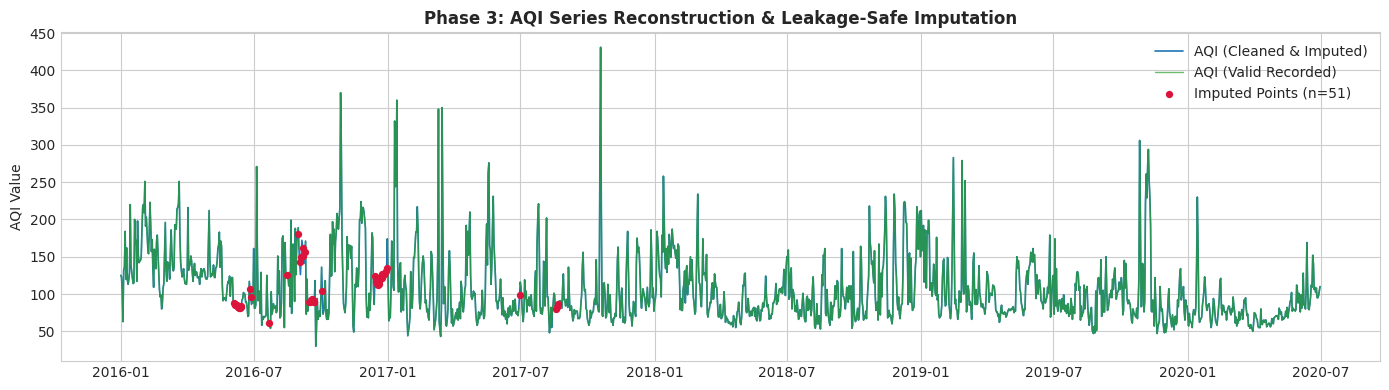

In [7]:
chennai_imputed = chennai_valid.copy()
train_st, train_en = SPLITS['train']
train_slice = chennai_valid.loc[train_st:train_en]

# Compute train DOY means for each feature (leakage-safe, ignoring NaNs including anomaly days)
doy_means = train_slice.groupby(train_slice.index.dayofyear)[['AQI'] + ALL9_POLLUTANTS].mean()

# Smooth climatology with 15-day circular rolling mean
smoothed_climatology = {}
for col in ['AQI'] + ALL9_POLLUTANTS:
    raw_doy = doy_means[col].dropna()
    if len(raw_doy) > 0:
        extended = pd.concat([raw_doy.iloc[-15:], raw_doy, raw_doy.iloc[:15]])
        smoothed = extended.rolling(15, center=True, min_periods=1).mean().iloc[15:-15]
        smoothed_climatology[col] = smoothed
    else:
        smoothed_climatology[col] = raw_doy

imputation_flags = pd.DataFrame(index=chennai_imputed.index)

for col in ['AQI'] + ALL9_POLLUTANTS:
    s = chennai_imputed[col].copy()
    is_na = s.isna()
    imputation_flags[f'{col}_imputed'] = 0
    
    # Identify contiguous blocks
    blocks = []
    in_block = False
    start_idx = None
    
    for i, (dt, val) in enumerate(is_na.items()):
        if val and not in_block:
            in_block = True
            start_idx = i
        elif not val and in_block:
            in_block = False
            blocks.append((start_idx, i - 1))
    if in_block:
        blocks.append((start_idx, len(is_na) - 1))
        
    for st_i, en_i in blocks:
        gap_len = en_i - st_i + 1
        block_dates = chennai_imputed.index[st_i:en_i+1]
        
        if gap_len <= 3:
            # Linear interpolation
            interpolated = chennai_imputed[col].interpolate(method='time', limit_direction='both')
            chennai_imputed.loc[block_dates, col] = interpolated.loc[block_dates]
            imputation_flags.loc[block_dates, f'{col}_imputed'] = 1
        elif 4 <= gap_len <= 30:
            # Train climatological DOY matching
            for b_dt in block_dates:
                d_val = b_dt.dayofyear
                if d_val in smoothed_climatology[col].index:
                    clim_val = smoothed_climatology[col].loc[d_val]
                else:
                    clim_val = train_slice[col].median()
                chennai_imputed.loc[b_dt, col] = clim_val
            imputation_flags.loc[block_dates, f'{col}_imputed'] = 2
        else:
            # > 30 days: left as NaN
            pass

print("=== Post-Imputation Missing Count ===")
print("AQI missing:", chennai_imputed['AQI'].isna().sum())
print("CORE pollutants missing:", chennai_imputed[CORE_POLLUTANTS].isna().sum().to_dict())
print("ALL9 pollutants missing:", chennai_imputed[ALL9_POLLUTANTS].isna().sum().to_dict())

print(f"\nRe-imputed values for confirmed Aug–Sep 2016 anomaly dates:")
for d in anomaly_dates:
    print(f"  {d.date()}: Imputed AQI = {chennai_imputed.loc[d, 'AQI']:.2f}, Imputed CO = {chennai_imputed.loc[d, 'CO']:.2f}")

# Verification plot
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(chennai_imputed.index, chennai_imputed['AQI'], color='#1f77b4', lw=1.2, label='AQI (Cleaned & Imputed)')
ax.plot(chennai_valid.index, chennai_valid['AQI'], color='#2ca02c', lw=1.0, alpha=0.7, label='AQI (Valid Recorded)')
imp_mask = imputation_flags['AQI_imputed'] > 0
if imp_mask.sum() > 0:
    ax.scatter(chennai_imputed.index[imp_mask], chennai_imputed['AQI'][imp_mask], 
               color='crimson', s=18, zorder=5, label=f'Imputed Points (n={imp_mask.sum()})')
ax.set_title('Phase 3: AQI Series Reconstruction & Leakage-Safe Imputation', fontsize=12, fontweight='bold')
ax.set_ylabel('AQI Value', fontsize=10)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p3_imputation_before_after.png'), dpi=300)
plt.show()

## Step 7: Spike Preservation & Upper-Bound-Only Winsorization

### Spike Preservation Policy
Authentic AQI spikes represent genuine atmospheric phenomena (e.g. Diwali firecrackers, Bhogi bonfires) and are **never trimmed or capped**.

### Strict Calendar Attribution Rule
- **Diwali (within $\pm 1$ day):**
  - Diwali 2016: 30 Oct 2016 (window: 29–31 Oct)
  - Diwali 2017: 19 Oct 2017 (window: 18–20 Oct)
  - Diwali 2018: 7 Nov 2018 (window: 6–8 Nov)
  - Diwali 2019: 27 Oct 2019 (window: 26–28 Oct)
- **Bhogi:** 13–14 January
- **New Year:** 31 December – 1 January
- **All other spikes:** Strictly labeled `"No matched event"`.

### Upper-Bound-Only Winsorization
- Pollutants are clipped at the **train set 99.5th percentile UPPER BOUND ONLY**.
- Lower clipping is completely omitted to preserve genuine clean atmospheric readings.

=== Top 15 AQI Spikes with Strict Calendar Attribution (Post-Anomaly Removal) ===


,AQI,Cause,Action Taken
Date,,,
2017-10-19,431.0,Diwali 2017,Preserved (Genuine Physical Peak)
2016-10-28,370.0,No matched event,Preserved (Genuine Physical Peak)
2017-01-13,360.0,Bhogi,Preserved (Genuine Physical Peak)
2017-03-16,350.0,No matched event,Preserved (Genuine Physical Peak)
2017-03-11,348.0,No matched event,Preserved (Genuine Physical Peak)
2017-01-10,332.0,No matched event,Preserved (Genuine Physical Peak)
2019-10-27,306.0,Diwali 2019,Preserved (Genuine Physical Peak)
2016-10-29,298.0,Diwali 2016,Preserved (Genuine Physical Peak)
2019-11-08,294.0,No matched event,Preserved (Genuine Physical Peak)


Saved p3_top_aqi_spikes.csv


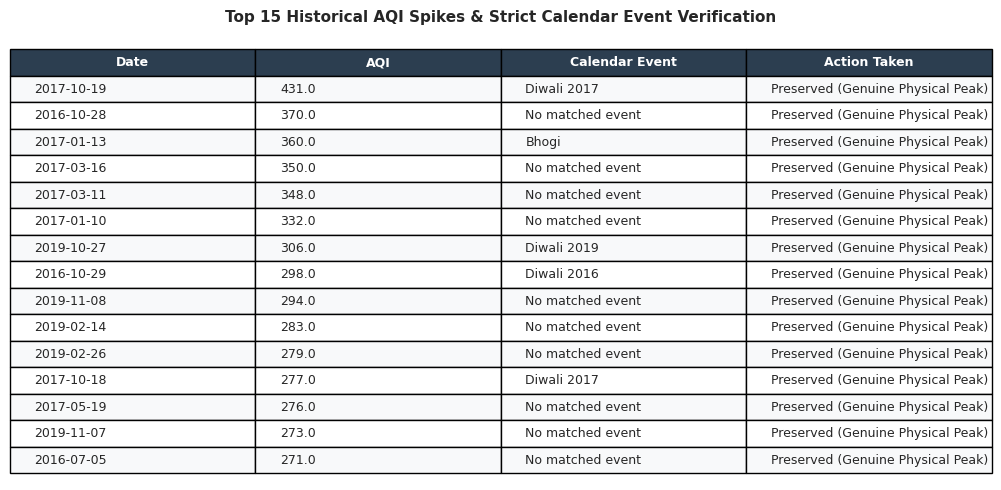

=== Upper-Bound Winsorization Summary (Train 99.5th Percentile Only) ===


,Train 99.5th Percentile,Total Clipped Days,Clip Percentage (%)
PM2.5,182.114,7.0,0.43
NO,26.575,13.0,0.79
NO2,40.212,8.0,0.49
NOx,40.788,18.0,1.10
CO,3.033,6.0,0.37
SO2,28.769,7.0,0.43
O3,72.189,11.0,0.67
Benzene,12.315,8.0,0.49
Toluene,18.258,7.0,0.43


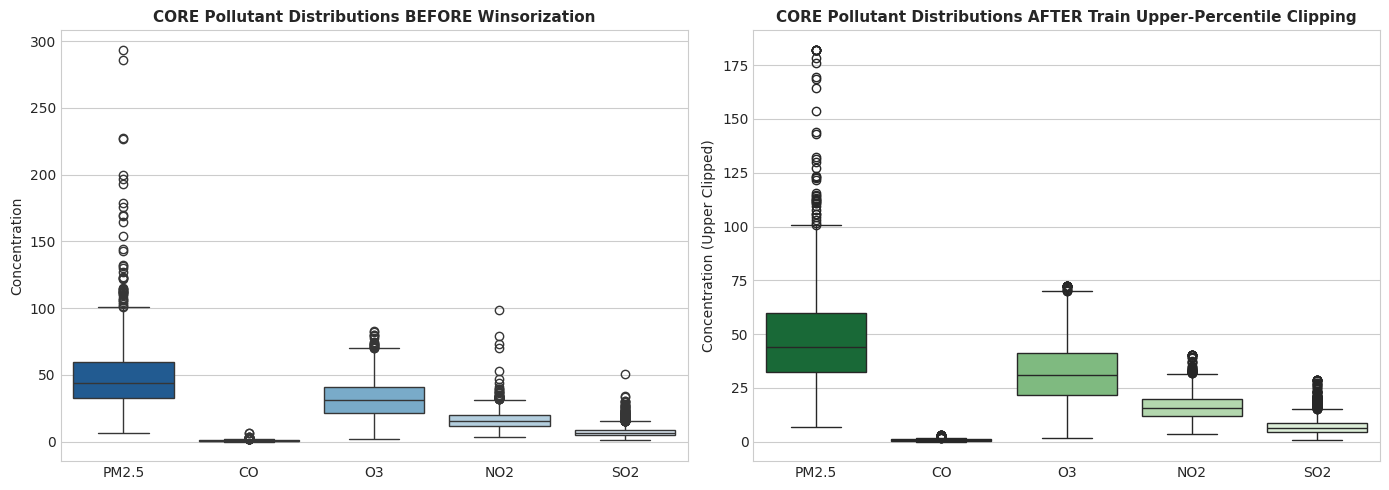

In [8]:
# 1. Top 15 AQI Spikes & Strict Calendar Event Matching
top15_spikes = chennai_imputed.nlargest(15, 'AQI')[['AQI']].copy()

def match_calendar_event(dt):
    year = dt.year
    month = dt.month
    day = dt.day
    # Diwali definitions (within +- 1 day)
    if year == 2016 and month == 10 and day in [29, 30, 31]:
        return "Diwali 2016"
    if year == 2017 and month == 10 and day in [18, 19, 20]:
        return "Diwali 2017"
    if year == 2018 and month == 11 and day in [6, 7, 8]:
        return "Diwali 2018"
    if year == 2019 and month == 10 and day in [26, 27, 28]:
        return "Diwali 2019"
    # Bhogi: 13-14 Jan
    if month == 1 and day in [13, 14]:
        return "Bhogi"
    # New Year: 31 Dec - 1 Jan
    if (month == 12 and day == 31) or (month == 1 and day == 1):
        return "New Year"
    return "No matched event"

top15_spikes['Cause'] = [match_calendar_event(idx) for idx in top15_spikes.index]
top15_spikes['Action Taken'] = "Preserved (Genuine Physical Peak)"
top15_spikes.index.name = 'Date'

print("=== Top 15 AQI Spikes with Strict Calendar Attribution (Post-Anomaly Removal) ===")
display(top15_spikes)

# Save to CSV
top15_spikes.to_csv(os.path.join(RES_DIR, 'p3_top_aqi_spikes.csv'))
print("Saved p3_top_aqi_spikes.csv")

# Save table figure
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis('tight')
ax.axis('off')
table_data = []
for idx, r in top15_spikes.reset_index().iterrows():
    table_data.append([r['Date'].strftime('%Y-%m-%d'), f"{r['AQI']:.1f}", r['Cause'], r['Action Taken']])

col_labels = ['Date', 'AQI', 'Calendar Event', 'Action Taken']
table = ax.table(cellText=table_data, colLabels=col_labels, loc='center', cellLoc='left')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.1, 1.4)
for (i, j), cell in table.get_celld().items():
    if i == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif i % 2 == 1:
        cell.set_facecolor('#f8f9fa')
plt.title('Top 15 Historical AQI Spikes & Strict Calendar Event Verification', fontsize=11, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p3_aqi_spike_events_table.png'), dpi=300)
plt.show()

# 2. Upper-Bound-Only Winsorization for ALL9 Pollutants
train_mask = (chennai_imputed.index >= train_st) & (chennai_imputed.index <= train_en)
train_data = chennai_imputed.loc[train_mask]

upper_bounds = {}
clip_counts = {}

chennai_winsorised = chennai_imputed.copy()

for col in ALL9_POLLUTANTS:
    u_bound = train_data[col].quantile(0.995)
    upper_bounds[col] = u_bound
    
    # Count exceedances across full series
    exceedances = (chennai_imputed[col] > u_bound).sum()
    clip_counts[col] = {
        'Train 99.5th Percentile': round(u_bound, 3),
        'Total Clipped Days': int(exceedances),
        'Clip Percentage (%)': round((exceedances / len(chennai_imputed)) * 100, 2)
    }
    # Upper-bound clipping only (no lower bound clipping)
    chennai_winsorised[col] = chennai_imputed[col].clip(upper=u_bound)

clipping_df = pd.DataFrame(clip_counts).T
print("=== Upper-Bound Winsorization Summary (Train 99.5th Percentile Only) ===")
display(clipping_df)

# Plot before/after boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=chennai_imputed[CORE_POLLUTANTS], ax=axes[0], palette='Blues_r')
axes[0].set_title('CORE Pollutant Distributions BEFORE Winsorization', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Concentration', fontsize=10)

sns.boxplot(data=chennai_winsorised[CORE_POLLUTANTS], ax=axes[1], palette='Greens_r')
axes[1].set_title('CORE Pollutant Distributions AFTER Train Upper-Percentile Clipping', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Concentration (Upper Clipped)', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p3_outlier_boxplots_clipping.png'), dpi=300)
plt.show()

## Step 8: Cyclical Calendar Encoding
To capture annual seasonality and weekly operational cycles, temporal indices are transformed into continuous circular trigonometric coordinates:
- **Day of Year ($365.25$-day cycle):** $\text{doy\_sin}$, $\text{doy\_cos}$
- **Day of Week ($7$-day cycle):** $\text{dow\_sin}$, $\text{dow\_cos}$
- **Weekend Indicator:** Binary flag ($1$ for Saturday/Sunday, $0$ for weekdays).

In [9]:
chennai_features = chennai_winsorised.copy()

doy = chennai_features.index.dayofyear
dow = chennai_features.index.dayofweek

chennai_features['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
chennai_features['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
chennai_features['dow_sin'] = np.sin(2 * np.pi * dow / 7.0)
chennai_features['dow_cos'] = np.cos(2 * np.pi * dow / 7.0)
chennai_features['is_weekend'] = (dow >= 5).astype(int)

calendar_features = ['doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'is_weekend']
print(f"Calendar features generated: {calendar_features}")
print(chennai_features[calendar_features].head(3))

Calendar features generated: ['doy_sin', 'doy_cos', 'dow_sin', 'dow_cos', 'is_weekend']
             doy_sin   doy_cos   dow_sin   dow_cos  is_weekend
Date                                                          
2016-01-01  0.017202  0.999852 -0.433884 -0.900969           0
2016-01-02  0.034398  0.999408 -0.974928 -0.222521           1
2016-01-03  0.051584  0.998669 -0.781831  0.623490           1


## Step 9: Chronological Partitioning
Time series forecasting strictly prohibits randomized shuffling. The dataset is segmented into four sequential partitions:
- **Train:** `2016-01-01` $\rightarrow$ `2018-12-31` ($1,096$ days)
- **Validation:** `2019-01-01` $\rightarrow$ `2019-08-31` ($243$ days)
- **Test:** `2019-09-01` $\rightarrow$ `2020-02-29` ($182$ days)
- **Stress-Test:** `2020-03-01` $\rightarrow$ `2020-06-30` ($122$ days, COVID-19 lockdown window)

=== Chronological Split Architecture ===


,Partition,Start Date,End Date,Total Days,Share (%)
0,Train,2016-01-01,2018-12-31,1096,66.7
1,Validation,2019-01-01,2019-08-31,243,14.8
2,Test,2019-09-01,2020-02-29,182,11.1
3,Stress-Test,2020-03-01,2020-06-30,122,7.4


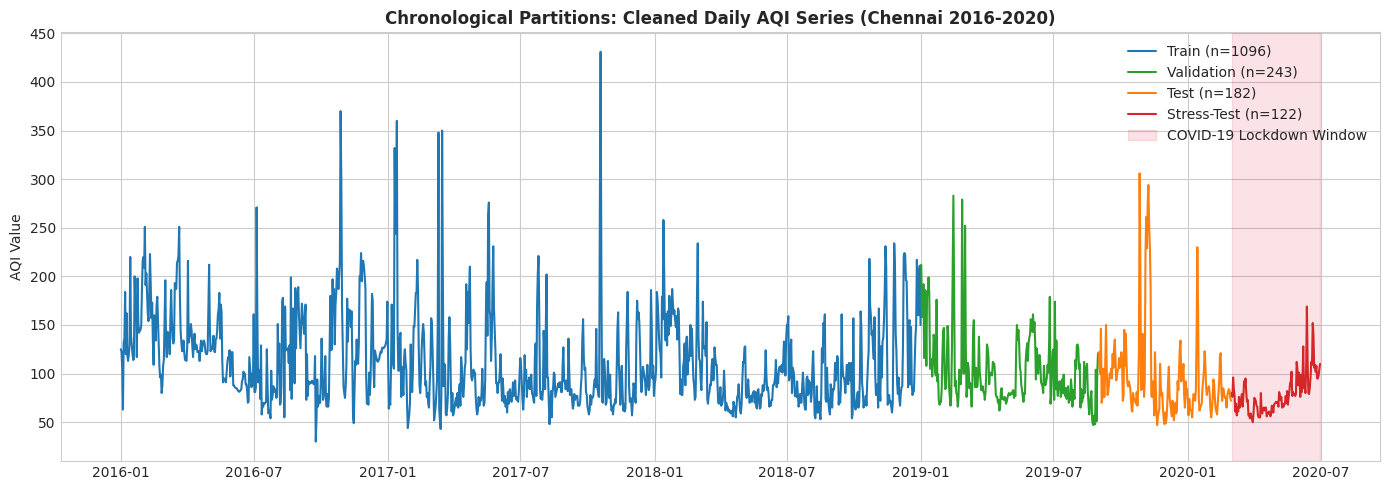

In [10]:
train_df = chennai_features.loc[SPLITS['train'][0]:SPLITS['train'][1]].copy()
val_df = chennai_features.loc[SPLITS['val'][0]:SPLITS['val'][1]].copy()
test_df = chennai_features.loc[SPLITS['test'][0]:SPLITS['test'][1]].copy()
stress_df = chennai_features.loc[SPLITS['stress'][0]:SPLITS['stress'][1]].copy()

split_counts = {
    'Partition': ['Train', 'Validation', 'Test', 'Stress-Test'],
    'Start Date': [SPLITS['train'][0], SPLITS['val'][0], SPLITS['test'][0], SPLITS['stress'][0]],
    'End Date': [SPLITS['train'][1], SPLITS['val'][1], SPLITS['test'][1], SPLITS['stress'][1]],
    'Total Days': [len(train_df), len(val_df), len(test_df), len(stress_df)],
    'Share (%)': [
        round(len(train_df) / len(chennai_features) * 100, 1),
        round(len(val_df) / len(chennai_features) * 100, 1),
        round(len(test_df) / len(chennai_features) * 100, 1),
        round(len(stress_df) / len(chennai_features) * 100, 1)
    ]
}
split_summary_df = pd.DataFrame(split_counts)
print("=== Chronological Split Architecture ===")
display(split_summary_df)

# Timeline figure
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_df.index, train_df['AQI'], color='#1f77b4', label=f"Train (n={len(train_df)})")
ax.plot(val_df.index, val_df['AQI'], color='#2ca02c', label=f"Validation (n={len(val_df)})")
ax.plot(test_df.index, test_df['AQI'], color='#ff7f0e', label=f"Test (n={len(test_df)})")
ax.plot(stress_df.index, stress_df['AQI'], color='#d62728', label=f"Stress-Test (n={len(stress_df)})")
ax.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-06-30'), color='crimson', alpha=0.12, label='COVID-19 Lockdown Window')

ax.set_title('Chronological Partitions: Cleaned Daily AQI Series (Chennai 2016-2020)', fontsize=12, fontweight='bold')
ax.set_ylabel('AQI Value', fontsize=10)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p3_final_cleaned_aqi_splits.png'), dpi=300)
plt.show()

## Step 10: Train-Isolated Min-Max Feature Scaling
To prevent lookahead contamination:
1. `MinMaxScaler` objects are fitted **exclusively on the Train partition** (`2016-01-01` $\rightarrow$ `2018-12-31`).
2. Three separate scalers are fitted:
   - Target variable (`AQI`) $\rightarrow$ `scaler_target.joblib`
   - Primary `CORE` feature subset $\rightarrow$ `scaler_features_core.joblib`
   - Extended `ALL9` feature subset $\rightarrow$ `scaler_features_all9.joblib`
3. Scalers transform Validation, Test, and Stress-Test partitions without re-fitting. Both unscaled and scaled CSVs are exported to `data/processed/`.

In [11]:
# 1. Target Scaler
scaler_target = MinMaxScaler(feature_range=(0, 1))
scaler_target.fit(train_df[[TARGET]])

print(f"Target Scaler fitted on Train:")
print(f"  Min: {scaler_target.data_min_[0]:.2f}")
print(f"  Max: {scaler_target.data_max_[0]:.2f} (NEW TARGET MAX post-anomaly removal)")

# 2. CORE Features Scaler
scaler_core = MinMaxScaler(feature_range=(0, 1))
scaler_core.fit(train_df[CORE_POLLUTANTS])

# 3. ALL9 Features Scaler
scaler_all9 = MinMaxScaler(feature_range=(0, 1))
scaler_all9.fit(train_df[ALL9_POLLUTANTS])

# Save fitted scalers with joblib
joblib.dump(scaler_target, os.path.join(MODELS_DIR, 'scaler_target.joblib'))
joblib.dump(scaler_core, os.path.join(MODELS_DIR, 'scaler_features_core.joblib'))
joblib.dump(scaler_all9, os.path.join(MODELS_DIR, 'scaler_features_all9.joblib'))

print("\nSaved fitted scalers to outputs/models/:")
print(" - scaler_target.joblib")
print(" - scaler_features_core.joblib")
print(" - scaler_features_all9.joblib")

# Helper function to generate scaled versions
def create_scaled_dataframe(df_in):
    df_out = df_in.copy()
    
    # Scaled Target
    df_out['AQI_scaled'] = scaler_target.transform(df_in[[TARGET]])
    
    # Scaled CORE Pollutants
    scaled_core_vals = scaler_core.transform(df_in[CORE_POLLUTANTS])
    for idx, c in enumerate(CORE_POLLUTANTS):
        df_out[f'{c}_scaled'] = scaled_core_vals[:, idx]
        
    # Scaled ALL9 Pollutants
    scaled_all9_vals = scaler_all9.transform(df_in[ALL9_POLLUTANTS])
    for idx, c in enumerate(ALL9_POLLUTANTS):
        df_out[f'{c}_scaled_all9'] = scaled_all9_vals[:, idx]
        
    return df_out

train_scaled_df = create_scaled_dataframe(train_df)
val_scaled_df = create_scaled_dataframe(val_df)
test_scaled_df = create_scaled_dataframe(test_df)
stress_scaled_df = create_scaled_dataframe(stress_df)
chennai_clean_full = pd.concat([train_df, val_df, test_df, stress_df])

# Export unscaled CSVs
train_df.to_csv(os.path.join(DATA_PROCESSED, 'train.csv'))
val_df.to_csv(os.path.join(DATA_PROCESSED, 'val.csv'))
test_df.to_csv(os.path.join(DATA_PROCESSED, 'test.csv'))
stress_df.to_csv(os.path.join(DATA_PROCESSED, 'stress.csv'))
chennai_clean_full.to_csv(os.path.join(DATA_PROCESSED, 'chennai_clean_full.csv'))

# Export scaled CSVs
train_scaled_df.to_csv(os.path.join(DATA_PROCESSED, 'train_scaled.csv'))
val_scaled_df.to_csv(os.path.join(DATA_PROCESSED, 'val_scaled.csv'))
test_scaled_df.to_csv(os.path.join(DATA_PROCESSED, 'test_scaled.csv'))
stress_scaled_df.to_csv(os.path.join(DATA_PROCESSED, 'stress_scaled.csv'))

print("\nSaved all unscaled and scaled CSVs to data/processed/")

Target Scaler fitted on Train:
  Min: 30.00
  Max: 431.00 (NEW TARGET MAX post-anomaly removal)

Saved fitted scalers to outputs/models/:
 - scaler_target.joblib
 - scaler_features_core.joblib
 - scaler_features_all9.joblib

Saved all unscaled and scaled CSVs to data/processed/


## Step 11: Final Pipeline Summary & Integrity Assertions
We execute verification assertions across all saved datasets and scalers to validate:
1. Exact row counts and calendar continuity across partitions.
2. Complete non-missingness ($0$ NaNs) for `AQI` and all `CORE` pollutants.
3. Verification that `AQI_scaled` on Train strictly spans $[0, 1]$.
4. Verification that `anomaly_removed` flag exists and identifies exactly 15 days.
5. Successful deserialization of all three fitted `MinMaxScaler` joblib artifacts.

In [12]:
# Verification Assertions
assert len(train_df) == 1096, f"Expected 1,096 train rows, got {len(train_df)}"
assert len(val_df) == 243, f"Expected 243 val rows, got {len(val_df)}"
assert len(test_df) == 182, f"Expected 182 test rows, got {len(test_df)}"
assert len(stress_df) == 122, f"Expected 122 stress rows, got {len(stress_df)}"
assert len(chennai_clean_full) == 1643, f"Expected 1,643 full rows, got {len(chennai_clean_full)}"

# Check anomaly flag
assert 'anomaly_removed' in chennai_clean_full.columns, "anomaly_removed column missing!"
assert chennai_clean_full['anomaly_removed'].sum() == 15, f"Expected 15 anomaly days, got {chennai_clean_full['anomaly_removed'].sum()}"

# Completeness in AQI and CORE
for s_name, s_df in [('Train', train_df), ('Validation', val_df), ('Test', test_df), ('Stress-Test', stress_df)]:
    assert s_df['AQI'].isna().sum() == 0, f"NaNs detected in {s_name} AQI"
    assert s_df[CORE_POLLUTANTS].isna().sum().sum() == 0, f"NaNs detected in {s_name} CORE pollutants"

# Train scaled bounds
assert np.isclose(train_scaled_df['AQI_scaled'].min(), 0.0), "Train AQI_scaled minimum is not 0"
assert np.isclose(train_scaled_df['AQI_scaled'].max(), 1.0), "Train AQI_scaled maximum is not 1"

# Check scalers
sc_tgt = joblib.load(os.path.join(MODELS_DIR, 'scaler_target.joblib'))
sc_cor = joblib.load(os.path.join(MODELS_DIR, 'scaler_features_core.joblib'))
sc_all9 = joblib.load(os.path.join(MODELS_DIR, 'scaler_features_all9.joblib'))

assert sc_tgt.n_features_in_ == 1, "scaler_target should have 1 feature"
assert sc_cor.n_features_in_ == 5, "scaler_core should have 5 features"
assert sc_all9.n_features_in_ == 9, "scaler_all9 should have 9 features"

print("==========================================================================")
print("ALL PREPROCESSING INTEGRITY ASSERTIONS PASSED SUCCESSFULLY!")
print(f"Total Calendar Days: {len(chennai_clean_full)} (2016-01-01 -> 2020-06-30)")
print("Partitions: Train=1096, Val=243, Test=182, Stress=122")
print("Target & CORE Completeness: 100.0% (Zero missing values)")
print(f"Target Scaler Bounds: [{sc_tgt.data_min_[0]:.1f}, {sc_tgt.data_max_[0]:.1f}]")
print("Anomaly Removed Days: 15 (Aug–Sep 2016, re-imputed with gap-adaptive rules)")
print("Scalers: Target (1), CORE (5), ALL9 (9) fitted on Train only and saved.")
print("==========================================================================")

ALL PREPROCESSING INTEGRITY ASSERTIONS PASSED SUCCESSFULLY!
Total Calendar Days: 1643 (2016-01-01 -> 2020-06-30)
Partitions: Train=1096, Val=243, Test=182, Stress=122
Target & CORE Completeness: 100.0% (Zero missing values)
Target Scaler Bounds: [30.0, 431.0]
Anomaly Removed Days: 15 (Aug–Sep 2016, re-imputed with gap-adaptive rules)
Scalers: Target (1), CORE (5), ALL9 (9) fitted on Train only and saved.
